Note: After you run this cell, the training and test data will be available in<br>
the file browser. (Click the folder icon on the left to view it)<br>
<br>
If you don't see the data after the cell completes, click the refresh button<br>
in the file browser (folder icon with circular arrow)

First, let's download and unzip the data

In [ ]:
import urllib.request
import zipfile
import os
import shutil

print("Downloading files...")
base_url = "https://github.com/byui-cse/cse450-course/raw/master/data/roadsigns/"
files_to_download = [
    "training1.zip",
    "training2.zip",
    "holdout.zip",
    "mini_holdout.zip",
    "mini_holdout_answers.csv"
]

# Download all files to the current directory
for file in files_to_download:
    if not os.path.exists(file):
        print(f"  Downloading {file}...")
        urllib.request.urlretrieve(base_url + file, file)

print("Unzipping files...")
zips = ["training1.zip", "training2.zip", "holdout.zip", "mini_holdout.zip"]
for zip_name in zips:
    if os.path.exists(zip_name):
        print(f"  Extracting {zip_name}...")
        with zipfile.ZipFile(zip_name, 'r') as zip_ref:
            zip_ref.extractall()

print("Merging training data...")
# Create the main training directory if it doesn't exist
os.makedirs("training", exist_ok=True)

# Move contents of training1 and training2 into the main training folder
for source_dir in ["training1", "training2"]:
    if os.path.exists(source_dir):
        for item in os.listdir(source_dir):
            shutil.move(os.path.join(source_dir, item), os.path.join("training", item))
        os.rmdir(source_dir) # Remove the now-empty directory

print("Cleaning up zip files...")
for zip_name in zips:
    if os.path.exists(zip_name):
        os.remove(zip_name)

print("Data ready.")

In [ ]:
import torch

# Check if CUDA is mathematically available
cuda_available = torch.cuda.is_available()
print(f"CUDA Available: {cuda_available}")

if cuda_available:
    # Check the specific GPU PyTorch sees
    print(f"GPU Device Name: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version PyTorch was built with: {torch.version.cuda}")
else:
    print("PyTorch is running on CPU only.")

Import libraries

In [ ]:
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

-----------------------------------------#<br>
2. set up augmentation and batching<br>
-----------------------------------------#

In [ ]:
image_size = (224, 224) # Standard for ViT
batch_size = 32
training_dir = 'training'
holdout_dir = 'mini_holdout'

Training transforms (Heavy augmentation for Phase 1)

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(image_size),
    transforms.RandomRotation(15), # Slight rotation for robustness
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Validation/Test transforms (Strictly preprocessing)

In [ ]:
test_transform = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Load datasets using the directory structure

In [ ]:
train_dataset = datasets.ImageFolder(root=training_dir, transform=train_transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)

In [ ]:
target_names = ['Speed_20', 'Speed_30', 'Speed_50', 'Speed_60', 'Speed_70',
               'Speed_80','Speed_Limit_Ends', 'Speed_100', 'Speed_120', 'Overtaking_Prohibited',
               'Overtakeing_Prohibited_Trucks', 'Priority', 'Priority_Road_Ahead', 'Yield', 'STOP',
               'Entry_Forbidden', 'Trucks_Forbidden', 'No_Entry(one-way traffic)', 'General Danger(!)', 'Left_Curve_Ahead',
               'Right_Curve_Ahead', 'Double_Curve', 'Poor_Surface_Ahead', 'Slippery_Surface_Ahead', 'Road_Narrows_On_Right',
               'Roadwork_Ahead', 'Traffic_Light_Ahead', 'Warning_Pedestrians', 'Warning_Children', 'Warning_Bikes',
               'Ice_Snow', 'Deer_Crossing', 'End_Previous_Limitation', 'Turning_Right_Compulsory', 'Turning_Left_Compulsory',
               'Ahead_Only', 'Straight_Or_Right_Mandatory', 'Straight_Or_Left_Mandatory', 'Passing_Right_Compulsory', 'Passing_Left_Compulsory',
               'Roundabout', 'End_Overtaking_Prohibition', 'End_Overtaking_Prohibition_Trucks']

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
import os

def audit_augmentations(image_path, transform, num_variations=10):
    # Load a single raw image directly
    raw_img = Image.open(image_path).convert("RGB")
    
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()
    
    for idx in range(num_variations):
        # Apply the training transform pipeline randomly each iteration
        aug_tensor = transform(raw_img)
        
        # Convert to matplotlib format
        img = aug_tensor.numpy().transpose((1, 2, 0))
        
        # Un-normalize
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)
        
        # Plot
        axes[idx].imshow(img)
        axes[idx].set_title(f"Variation {idx+1}", fontweight='bold')
        axes[idx].axis('off')
        
    plt.suptitle("Augmentation Entropy on a Single Image", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()



# You will need to provide the path to ANY single training image file
audit_augmentations("training/00001/00002_00007.jpg", train_transform)

-----------------------------#<br>
3. architecture for the STN<br>
-----------------------------#

In [ ]:
class ParametricSTN(nn.Module):
    def __init__(self):
        super().__init__()
        # A lightweight CNN to predict the 3 parameters
        self.loc_net = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=7, stride=2, padding=3),
            nn.ReLU(True),
            nn.MaxPool2d(2, stride=2),
            nn.Conv2d(8, 16, kernel_size=5, stride=2, padding=2),
            nn.ReLU(True),
            nn.MaxPool2d(2, stride=2),
            nn.Flatten(),
            nn.Linear(16 * 14 * 14, 64),
            nn.ReLU(True)
        )
        self.fc_out = nn.Linear(64, 3) # [rotation, scale, brightness]

        # Initialize to Identity Transform: rot=0, scale=1, brightness=0
        nn.init.zeros_(self.fc_out.weight)
        self.fc_out.bias.data.copy_(torch.tensor([0.0, 1.0, 0.0]))
    def forward(self, x):
        params = self.fc_out(self.loc_net(x))
        rot, scale, bright = params[:, 0], params[:, 1], params[:, 2]

        # Construct the 2x3 affine matrix for each item in the batch
        cos_a = torch.cos(rot)
        sin_a = torch.sin(rot)

        # Matrix: [[scale*cos, -scale*sin, 0], [scale*sin, scale*cos, 0]]
        # Shape needs to be (N, 2, 3)
        theta = torch.zeros(x.size(0), 2, 3, device=x.device)
        theta[:, 0, 0] = scale * cos_a
        theta[:, 0, 1] = scale * -sin_a
        theta[:, 1, 0] = scale * sin_a
        theta[:, 1, 1] = scale * cos_a

        # Apply spatial warp
        grid = F.affine_grid(theta, x.size(), align_corners=False)
        x_warped = F.grid_sample(x, grid, align_corners=False)

        # Apply brightness adjustment (broadcasted to spatial dimensions)
        x_out = x_warped + bright.view(-1, 1, 1, 1)
        return x_out

-------------------#<br>
4. build the ViT<br>
-------------------#

In [ ]:
import timm

class HybridTrafficSignModel(nn.Module):
    def __init__(self, num_classes=43):
        super().__init__()
        self.stn = ParametricSTN()
        
        # Pass num_classes directly. timm handles the head replacement automatically.
        self.vit = timm.create_model('mobilevit_xs', pretrained=True, num_classes=num_classes)
        
    def forward(self, x, apply_stn=True):
        if apply_stn:
            x = self.stn(x)
        return self.vit(x)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

model = HybridTrafficSignModel(num_classes=43).to(device)
criterion = nn.CrossEntropyLoss()

-------------------------#<br>
5. train only the ViT<br>
-------------------------#

In [ ]:


def train_epoch(model, dataloader, optimizer, apply_stn):
    model.train()
    total_loss = 0
    for images, labels in tqdm(dataloader, desc="Training"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images, apply_stn=apply_stn)
        loss = criterion(outputs, labels)
        loss.backward()

        # Gradient clipping to prevent explosions
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(dataloader)

In [ ]:
print("--- Phase 1: Training ViT Backbone ---")
# Optimizer only handles ViT parameters
optimizer_vit = optim.Adam(model.vit.parameters(), lr=1e-4)

In [ ]:
for epoch in range(6): # Short pre-training is usually sufficient
    loss = train_epoch(model, train_loader, optimizer_vit, apply_stn=False)
    print(f"Epoch {epoch+1} Loss: {loss:.4f}")

In [ ]:
save_path = "mobilevit_traffic_signs.pth"

# Extract the weights and save them to your drive
torch.save(model.state_dict(), save_path)

print(f"Weights successfully saved to: {save_path}")

-----------------------------#<br>
6. train STN with frozen ViT<br>
-----------------------------#

In [ ]:
print("--- Phase 2: Training STN (Frozen Backbone) ---")
# Freeze ViT
for param in model.vit.parameters():
    param.requires_grad = False
# Ensure STN is unfrozen
for param in model.stn.parameters():
    param.requires_grad = True

Optimizer only handles STN parameters

In [ ]:
optimizer_stn = optim.Adam(model.stn.parameters(), lr=1e-4)

In [ ]:
for epoch in range(2):
    loss = train_epoch(model, train_loader, optimizer_stn, apply_stn=True)
    print(f"Epoch {epoch+1} Loss: {loss:.4f}")

-----------------------------#<br>
7. Train both models together<br>
-----------------------------#

In [ ]:
print("--- Phase 3: End-to-End Fine-tuning ---")
# Unfreeze ViT
for param in model.vit.parameters():
    param.requires_grad = True

Optimizer handles everything, at a lower learning rate

In [ ]:
optimizer_all = optim.Adam(model.parameters(), lr=1e-5)

In [ ]:
for epoch in range(2):
    loss = train_epoch(model, train_loader, optimizer_all, apply_stn=True)
    print(f"Epoch {epoch+1} Loss: {loss:.4f}")

------------------------------------#<br>
8. Test for classification metrics<br>
------------------------------------#

In [ ]:
import pandas as pd
import os
from PIL import Image
from torch.utils.data import Dataset

In [ ]:
class CSVLabelDataset(Dataset):
    def __init__(self, image_dir, csv_file, transform=None):
        self.image_dir = image_dir
        self.transform = transform
        # CSV is of the form 'filename' and 'ClassID'
        self.data = pd.read_csv(csv_file)
    def __len__(self):
        return len(self.data)
    def __getitem__(self, idx):
        # Extract filename and label from the dataframe row
        # Adjust 'filename' and 'label' to match your CSV's actual header names
        img_name = self.data.iloc[idx]['Filename']
        label = int(self.data.iloc[idx]['ClassId'])
        img_path = os.path.join(self.image_dir, img_name)
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

In [ ]:
from sklearn.metrics import accuracy_score

1. Setup the dataset and loader<br>
Assuming test_transform is already defined

In [ ]:
test_dataset = CSVLabelDataset(
    image_dir='holdout',
    csv_file='mini_holdout_answers.csv',
    transform=test_transform
)
# Using batch_size=32 for faster evaluation
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, shuffle=False)

2. Evaluation Loop

In [ ]:
# Load in a model if necessary
saved_weights = torch.load('Hybrid_model_v2.pth', weights_only=True)
model.load_state_dict(saved_weights)

In [ ]:
model.eval()
all_preds = []
all_labels = []
all_probs = []

In [ ]:
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        probs, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

3. Calculate and print accuracy

In [25]:
acc = accuracy_score(all_labels, all_preds)
print(f"Model Accuracy: {acc * 100:.2f}%")

#all_preds.to_csv

Model Accuracy: 98.01%


In [27]:
class UnlabeledDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.transform = transform
        # Get a sorted list of all image files
        self.image_files = sorted([f for f in os.listdir(image_dir) if f.endswith(('.jpg', '.png'))])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]
        img_path = os.path.join(self.image_dir, img_name)
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, img_name # Return name to keep track of predictions

In [30]:
# Setup
test_dataset = UnlabeledDataset(image_dir='holdout', transform=test_transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

model.eval()
all_predictions = []

with torch.no_grad():
    for images, names in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        
        all_predictions.extend(preds.cpu().numpy())

# Create DataFrame and save
results_df = pd.DataFrame({
    'predictions': all_predictions
})

results_df.to_csv('predictions.csv', index=False)
print("Predictions saved to predictions.csv")

Predictions saved to predictions.csv


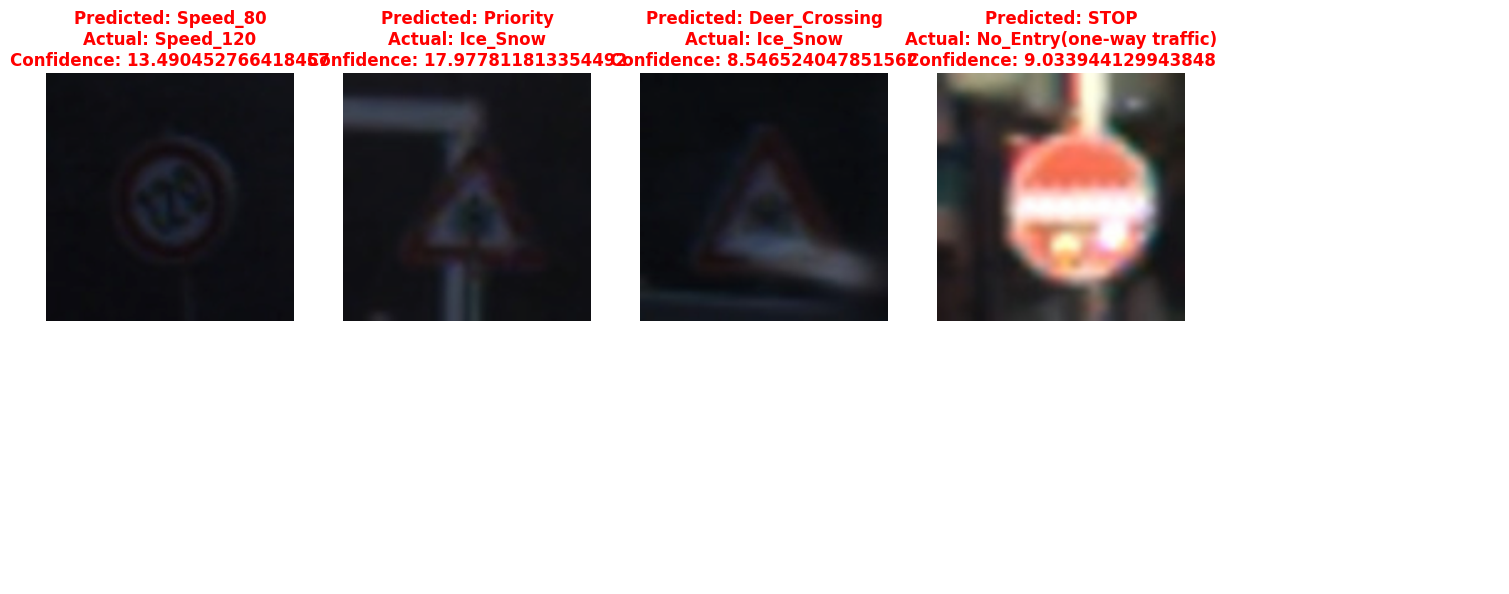

In [26]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_failures_from_lists(dataset, all_preds, all_labels, all_probs, num_images=10):
    # Find the exact indices where predictions don't match the ground truth
    mismatch_indices = [i for i, (p, t) in enumerate(zip(all_preds, all_labels)) if p != t]
    all_indices = [i for i, (p, t) in enumerate(zip(all_preds, all_labels))]

    if not mismatch_indices:
        print("No failures found! (Accuracy is 100%)")
        return

    # Limit to the requested number of images
    indices_to_plot = mismatch_indices[:num_images]
    #indices_to_plot = all_indices[:num_images]

    # Set up the matplotlib grid (2 rows, 5 columns)
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()

    for idx, dataset_idx in enumerate(indices_to_plot):
        # Extract the raw image tensor directly from the dataset using the index
        img_tensor, true_label = dataset[dataset_idx]
        predicted_label = all_preds[dataset_idx]
        confidence = all_probs[dataset_idx]
        
        # Transpose tensor to match matplotlib's (Height, Width, Color) requirement
        img = img_tensor.numpy().transpose((1, 2, 0))

        # Undo the ImageNet normalization
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)

        # Plot the image and add the text
        axes[idx].imshow(img)
        axes[idx].set_title(f"Predicted: {target_names[predicted_label]}\nActual: {target_names[true_label]}\nConfidence: {confidence}", 
                            color='red', fontweight='bold')
        axes[idx].axis('off')

    # Clear the grid lines for any unused subplots if there are fewer than 10 errors
    for i in range(len(indices_to_plot), len(axes)):
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

# Run the visualization tool
visualize_failures_from_lists(test_dataset, all_preds, all_labels, all_probs)


## Testing the model<br>
Once you have built and trained your model, the next step is to run the mini holdout images through it and see how well your model does at making predictions for images it has never seen before.<br>
Since loading these images and formatting them for the model can be tricky, you may find the following code useful. This code only uses your model to predict the class label for a given image. You'll still need to compare those predictions to the "ground truth" class labels in `mini_holdout_answers.csv` to evaluate how well the model does.<br>
Previously, you were given a file that would check your results. This time you're given the answers to the first mini holdout dataset. You'll need to compare those predictions against the "ground truth" class labels in `mini_holdout_answers.csv` to evaluate how well the model does.<br>
Make sure to use the insights gained from the mini hold out dataset in your executive summary.<br>
```<br>
from tensorflow.keras.preprocessing import image_dataset_from_directory<br>
test_dir = '/content/'<br>
test_datagen = ImageDataGenerator(rescale=1./255)<br>
test_generator = test_datagen.flow_from_directory(<br>
        test_dir,<br>
        classes=['mini_holdout'],<br>
        target_size=image_size,<br>
        class_mode='sparse',<br>
        shuffle=False)<br>
probabilities = model.predict(test_generator)<br>
predictions = [np.argmax(probas) for probas in probabilities]<br>
```<br>
##Mini Hold out Dataset<br>
Once you feel confident, you will need to predict for the full holdout dataset using the following code, and submit your csv file:<br>
```<br>
from tensorflow.keras.preprocessing import image_dataset_from_directory<br>
test_dir = '/content/'<br>
test_datagen = ImageDataGenerator(rescale=1./255)<br>
test_generator = test_datagen.flow_from_directory(<br>
        test_dir,<br>
        classes=['holdout'],<br>
        target_size=image_size,<br>
        class_mode='sparse',<br>
        shuffle=False)<br>
probabilities = model.predict(test_generator)<br>
predictions = [np.argmax(probas) for probas in probabilities]<br>
```<br>
